In [1]:
import pandas as pd

#### READING THE DATASET

In [2]:
df = pd.read_csv("Online Retail.csv",encoding="latin1")

In [3]:
# latin1 was used to fix unicodedecode error.This usually means Pandas cannote decode the file using its default text encoding.b

In [4]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 8.26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 8.26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 8.26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 8.26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 8.26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,09-12-2011 12.50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,09-12-2011 12.50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,09-12-2011 12.50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,09-12-2011 12.50,4.15,12680.0,France


# PART 1

## Exploratory Data Analysis

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [6]:
df.shape

(541909, 8)

In [7]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [8]:
df.isnull()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
541904,False,False,False,False,False,False,False,False
541905,False,False,False,False,False,False,False,False
541906,False,False,False,False,False,False,False,False
541907,False,False,False,False,False,False,False,False


In [9]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [10]:
df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
541904    False
541905    False
541906    False
541907    False
541908    False
Length: 541909, dtype: bool

In [11]:
print(df.duplicated().sum())

5268


##### after doing eda i found that there is only null values in customer id and description
#####  and there are 5268 duplicate values.

#### Checking outliers

##### My target variable is quantity ,so I am checking outliers in Quantity and Unitprice

###### BOX PLOT

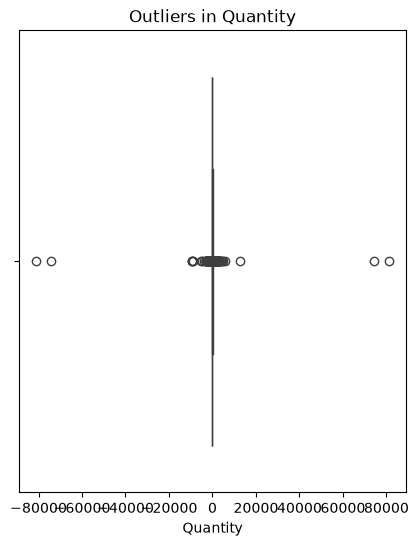

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(5,6))
sns.boxplot(x=df['Quantity'])
plt.title("Outliers in Quantity")
plt.show()

In [13]:
#the visulaization shows several extreme values beyond the normal range.
#indicating unusal quantity transactions in the dataset.

### Box plot for unit price

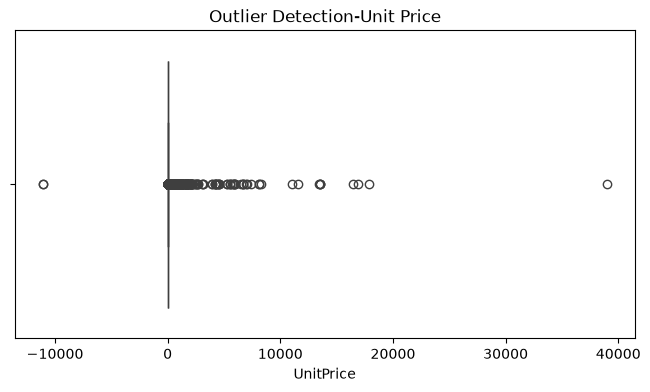

In [14]:

plt.figure(figsize=(8,4))
sns.boxplot(x=df['UnitPrice'])
plt.title("Outlier Detection-Unit Price")
plt.show()
            

In [15]:
#a box plot was created to identify outliers in the unit price.
# the plot shows that several extreme values(high positive and negative)

### Calculating IQR

In [16]:
Q1 = df["Quantity"].quantile(0.25)
Q3 = df["Quantity"].quantile(0.75)
IQR = Q3 -Q1
lower_limit = Q1-1.5*IQR
upper_limit = Q3+1.5*IQR
print("Lower limit:",lower_limit)
print("Upper limit:",upper_limit)

Lower limit: -12.5
Upper limit: 23.5


##### counting outliers

In [17]:
outliers =df[
    (df['Quantity']<lower_limit)|
    (df['Quantity']>upper_limit)
    ]
print("Number of outliers:",outliers)

Number of outliers:        InvoiceNo StockCode                         Description  Quantity  \
9         536367     84879       ASSORTED COLOUR BIRD ORNAMENT        32   
26        536370     22728           ALARM CLOCK BAKELIKE PINK        24   
27        536370     22727           ALARM CLOCK BAKELIKE RED         24   
30        536370     21883                    STARS GIFT TAPE         24   
31        536370     10002         INFLATABLE POLITICAL GLOBE         48   
...          ...       ...                                 ...       ...   
541876    581585     84945  MULTI COLOUR SILVER T-LIGHT HOLDER        24   
541882    581585     21916     SET 12 RETRO WHITE CHALK STICKS        24   
541883    581585     84692         BOX OF 24 COCKTAIL PARASOLS        25   
541891    581586     23275    SET OF 3 HANGING OWLS OLLIE BEAK        24   
541892    581586     21217       RED RETROSPOT ROUND CAKE TINS        24   

             InvoiceDate  UnitPrice  CustomerID         Country  
9

In [18]:
#check the minimum and maximum
print(df['Quantity'].min())
print(df['Quantity'].max())

-80995
80995


In [19]:
# Count negative quantities

df[df['Quantity'] < 0].head(10)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,01-12-2010 9.41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,01-12-2010 9.49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,01-12-2010 10.24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,01-12-2010 10.24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,01-12-2010 10.24,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,01-12-2010 10.24,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,01-12-2010 10.24,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,01-12-2010 10.24,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,01-12-2010 10.24,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,01-12-2010 12.38,4.25,17897.0,United Kingdom


In [20]:
## count positive quantities
df[df['Quantity'] > 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 8.26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 8.26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 8.26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 8.26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 8.26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,01-12-2010 8.26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,01-12-2010 8.26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,01-12-2010 8.28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,01-12-2010 8.28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,01-12-2010 8.34,1.69,13047.0,United Kingdom


## DATA PREPROCESSING

In [21]:
#handling missing values
#removing duplicates
#handling negatives values.
#handling outliers
#correcting data 
#preparing the dataset for modelling

In [22]:
#before moving to the data preprocessing i am making a copy of the dataset , to preserve the original dataset

In [23]:
df_clean=df.copy()  #preserving the original dataset

In [24]:
df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 8.26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 8.26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 8.26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 8.26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 8.26,3.39,17850.0,United Kingdom


#### Checking duplicates

In [25]:
df_clean.duplicated().sum()

np.int64(5268)

In [26]:
df_clean.drop_duplicates(inplace=True)

In [27]:
#inplace=True is used to modify the original dataframe directly instead of creating a new dataframe

In [28]:
df_clean.duplicated().sum()

np.int64(0)

#### HANDLING MISSING VALUES

In [29]:
#missing values
df_clean.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

In [30]:
#calculating the percentage of missing values.
(df_clean.isnull().sum() / len(df_clean)) *100

InvoiceNo       0.000000
StockCode       0.000000
Description     0.270945
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     25.163377
Country         0.000000
dtype: float64

In [31]:
#investigating the remaining 112
missing_desc = df_clean[df_clean['Description'].isnull()]
print("Remaining missing descriptions:",len(missing_desc))
missing_desc[['StockCode','Description']].drop_duplicates()

Remaining missing descriptions: 1454


,StockCode,Description
622,22139,NaN
1970,21134,NaN
1971,22145,NaN
1972,37509,NaN
1987,85226A,NaN
...,...,...
533712,22689,NaN
535322,84581,NaN
535326,23406,NaN
535332,21620,NaN


Some StockCodes might not have any available description elsewhere in the dataset.
If ABC123 has no other description, pandas cannot determine what description belongs to it.    

In [32]:
#fill missing description
description_map = (
    df_clean.dropna(subset=['Description'])
    .groupby('StockCode')['Description']
    .agg(lambda x: x.mode().iloc[0])
)

df_clean['Description'] = (
    df_clean['Description']
    .fillna(df_clean['StockCode'].map(description_map))
)

for the rest of the 112 missing values in description i am using a placeholder instead of guessing the actual product name.

In [33]:
df_clean['Description'] = df_clean['Description'].fillna(
    'Unknown Description'
)

In [34]:
df_clean.isnull().sum()

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

REMOVING CUSTOMER ID COLUMN

The Customer ID column contains a large number of missing values.Since our project focuses on product -level demand forecasting rather than customer-level analysis,this column is not essential for our prediction.

    If I drop the missing customerID rows, which would result in losing genuine transaction and sales quantity information,so I decided to remove the entire customerid column.This preserves the remaining transaction records and their associated product quantities.

In [35]:
df_clean.drop(columns=['CustomerID'],inplace=True)

#### FILTERING QUANTITY

In [36]:
df_clean['Quantity'].describe()

count    536641.000000
mean          9.620029
std         219.130156
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

In [37]:
print("Negative quantities:",
      (df_clean['Quantity'] < 0).sum())

print("Zero quantities:",
      (df_clean['Quantity'] == 0).sum())

print("Positive quantities:",
      (df_clean['Quantity'] > 0).sum())

Negative quantities: 10587
Zero quantities: 0
Positive quantities: 526054


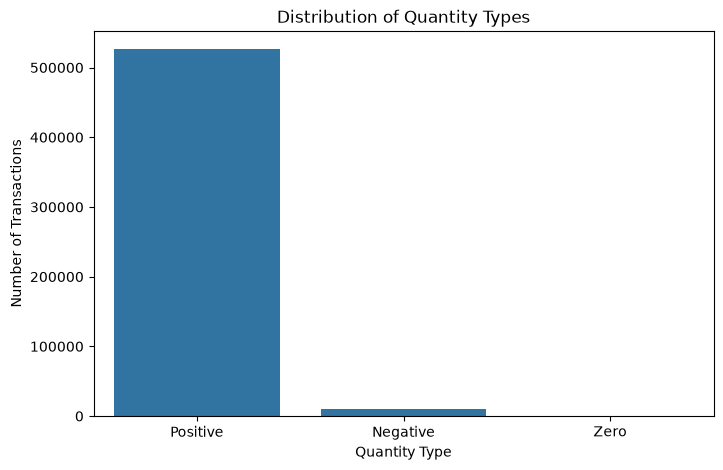

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

quantity_types = [
    (df_clean['Quantity'] > 0).sum(),
    (df_clean['Quantity'] < 0).sum(),
    (df_clean['Quantity'] == 0).sum()
]

labels = ['Positive', 'Negative', 'Zero']

plt.figure(figsize=(8, 5))
sns.barplot(x=labels, y=quantity_types)

plt.title('Distribution of Quantity Types')
plt.xlabel('Quantity Type')
plt.ylabel('Number of Transactions')

plt.show()

In [39]:
#negative_sales
negative_sales = df_clean[
    (~df_clean['InvoiceNo'].astype(str).str.startswith('C')) &
    (df_clean['Quantity'] < 0)
]
negative_sales.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,Country
2406,536589,21777,RECIPE BOX WITH METAL HEART,-10,01-12-2010 16.50,0.0,United Kingdom
4347,536764,84952C,MIRROR LOVE BIRD T-LIGHT HOLDER,-38,02-12-2010 14.42,0.0,United Kingdom
7188,536996,22712,CARD DOLLY GIRL,-20,03-12-2010 15.30,0.0,United Kingdom
7189,536997,22028,PENNY FARTHING BIRTHDAY CARD,-20,03-12-2010 15.30,0.0,United Kingdom
7190,536998,85067,CREAM SWEETHEART WALL CABINET,-6,03-12-2010 15.30,0.0,United Kingdom
7192,537000,21414,SCALLOP SHELL SOAP DISH,-22,03-12-2010 15.32,0.0,United Kingdom
7193,537001,21653,Unknown Description,-6,03-12-2010 15.33,0.0,United Kingdom
7195,537003,85126,LARGE ROUND CUTGLASS CANDLESTICK,-2,03-12-2010 15.33,0.0,United Kingdom
7196,537004,21814,HEART T-LIGHT HOLDER,-30,03-12-2010 15.34,0.0,United Kingdom
7197,537005,21692,SILVER LATTICE VANILLA CANDLE POT,-70,03-12-2010 15.35,0.0,United Kingdom


In [40]:
print("Shape:", negative_sales.shape)

Shape: (1336, 7)


In [41]:
negative_sales.describe()

,Quantity,UnitPrice
count,1336.000000,1336.0
mean,-154.907934,0.0
std,588.292456,0.0
min,-9600.000000,0.0
25%,-84.000000,0.0
50%,-30.000000,0.0
75%,-8.000000,0.0
max,-1.000000,0.0


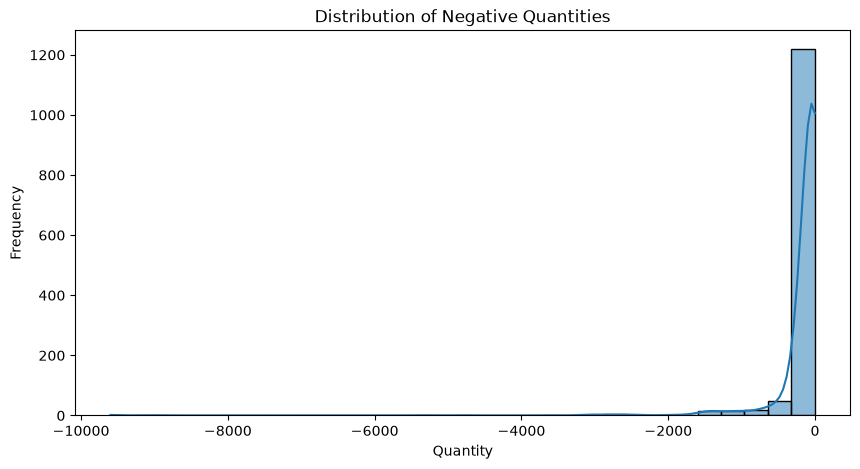

In [42]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=negative_sales,
    x='Quantity',
    bins=30,
    kde=True
)

plt.title('Distribution of Negative Quantities')
plt.xlabel('Quantity')
plt.ylabel('Frequency')

plt.show()

In [43]:
negative_sales[
    ['StockCode', 'Description', 'Quantity', 'UnitPrice']
].head(20)

,StockCode,Description,Quantity,UnitPrice
2406,21777,RECIPE BOX WITH METAL HEART,-10,0.0
4347,84952C,MIRROR LOVE BIRD T-LIGHT HOLDER,-38,0.0
7188,22712,CARD DOLLY GIRL,-20,0.0
7189,22028,PENNY FARTHING BIRTHDAY CARD,-20,0.0
7190,85067,CREAM SWEETHEART WALL CABINET,-6,0.0
7192,21414,SCALLOP SHELL SOAP DISH,-22,0.0
7193,21653,Unknown Description,-6,0.0
7195,85126,LARGE ROUND CUTGLASS CANDLESTICK,-2,0.0
7196,21814,HEART T-LIGHT HOLDER,-30,0.0
7197,21692,SILVER LATTICE VANILLA CANDLE POT,-70,0.0


In [44]:
negative_sales['Description'].value_counts().head(10)

Description
check                     120
Unknown Description        97
damages                    45
damaged                    42
?                          41
sold as set on dotcom      20
Damaged                    14
thrown away                 9
Unsaleable, destroyed.      9
??                          7
Name: count, dtype: int64

In [45]:
negative_sales['Description'].value_counts()

Description
check                              120
Unknown Description                 97
damages                             45
damaged                             42
?                                   41
                                  ... 
wet                                  1
wet boxes                            1
DOG TOY WITH PINK CROCHET SKIRT      1
????damages????                      1
lost                                 1
Name: count, Length: 785, dtype: int64

In [46]:
print("Zero UnitPrice:",
      (negative_sales['UnitPrice'] == 0).sum())

print("Non-zero UnitPrice:",
      (negative_sales['UnitPrice'] != 0).sum())

Zero UnitPrice: 1336
Non-zero UnitPrice: 0


### Investigating Negative Quantity Transactions

During the investigation, we identified 1,336 negative quantity records outside cancelled invoices. All these records had a UnitPrice of zero.

Further examination of their descriptions revealed entries such as damaged, damages, thrown away, unsaleable and unknown descriptions.

These observations suggest that the records may represent stock adjustments or other non-sales transactions rather than ordinary product sales. Since our project focuses on forecasting actual product demand, these records will be excluded from the sales forecasting dataset.

In [47]:
print("Cancelled invoices:",
      df_clean['InvoiceNo'].astype(str).str.startswith('C').sum())

Cancelled invoices: 9251


In [48]:
#Identify cancelled transactions
cancelled = df_clean['InvoiceNo'].astype(str).str.startswith('C')

# Count cancelled transaction rows
print("Cancelled transaction rows:", cancelled.sum())

# Count unique cancelled invoices
print("Unique cancelled invoices:",
      df_clean.loc[cancelled, 'InvoiceNo'].nunique())

# Count negative quantities
print("Negative quantity rows:",
      (df_clean['Quantity'] < 0).sum())

# Negative quantities in cancelled invoices
print("Negative quantities in cancelled invoices:",
      (cancelled & (df_clean['Quantity'] < 0)).sum())

# Negative quantities outside cancelled invoices
print("Negative quantities outside cancelled invoices:",
      ((~cancelled) & (df_clean['Quantity'] < 0)).sum())

Cancelled transaction rows: 9251
Unique cancelled invoices: 3836
Negative quantity rows: 10587
Negative quantities in cancelled invoices: 9251
Negative quantities outside cancelled invoices: 1336


rom this ,there are 9251 transaction rows associated with cancelled invoices.

All these rows have negative quantities.

Another 1336 rows have negative quantites but are not marked as cancelled invoices.

These additional negative quantities may represent product returns.

In [49]:
print("Cancelled invoices:", cancelled.sum())

print("Negative quantities outside cancellations:",
      len(negative_sales))

print("Total records to investigate:",
      cancelled.sum() + len(negative_sales))

Cancelled invoices: 9251
Negative quantities outside cancellations: 1336
Total records to investigate: 10587


In [50]:
print("Cancelled invoices:",
      df_clean['InvoiceNo'].astype(str).str.startswith('C').sum())

Cancelled invoices: 9251


In [51]:
# Remove cancelled invoices and negative quantities
df_clean = df_clean[
    (~df_clean['InvoiceNo'].astype(str).str.startswith('C')) &
    (df_clean['Quantity'] > 0)
].copy()

In [52]:
print("New dataset shape:", df_clean.shape)

print("Negative quantities:",
      (df_clean['Quantity'] < 0).sum())

print("Cancelled invoices:",
      df_clean['InvoiceNo'].astype(str).str.startswith('C').sum())

New dataset shape: (526054, 7)
Negative quantities: 0
Cancelled invoices: 0


## Removing Cancelled Transactions and negative Quantities

After investigating cancelled invoices and negative quantity records, I have removed 9,251 cancelled transaction rows and 1336 additional negative quantity records.

This filtering ensures that the forecasting dataset contains only positive_quantity transactions,allowing us to focus on actual recorded product sales demand.After filtering,the dataset contains 526,054 rows and 7 columns.


Cancelled transactions should not be treated as genuine sales,negative quantities may represent returns,positive quantities represent recorded sales.

from this ,there are 9251 transaction rows associated with cancelled invoices.
    
All these rows have negative quantities.
    
Another 1336 rows have negative quantites but are not marked as cancelled invoices.
    
These additional negative quantities may represent product returns.

## DETECTING OUTLIERS IN QUANTITY

In [53]:
df_clean['Quantity'].describe()

count    526054.000000
mean         10.730874
std         157.591838
min           1.000000
25%           1.000000
50%           4.000000
75%          11.000000
max       80995.000000
Name: Quantity, dtype: float64

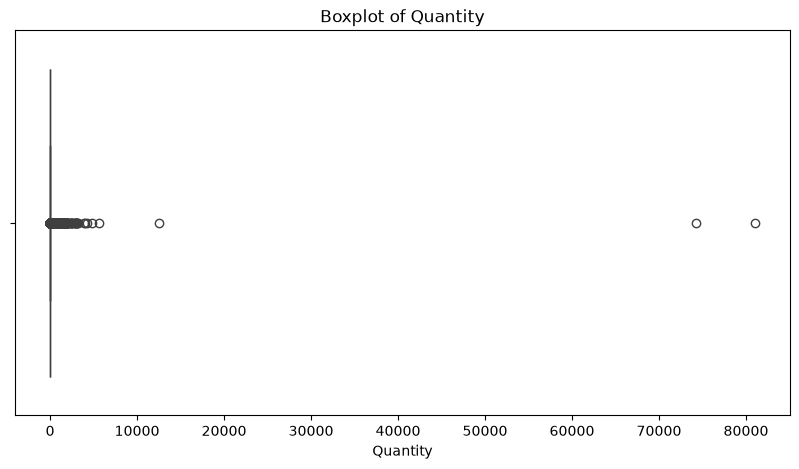

In [54]:
plt.figure(figsize=(10,5))
sns.boxplot(x= df_clean['Quantity'])
plt.title('Boxplot of Quantity')
plt.xlabel('Quantity')
plt.show()


##### Calculate IQR

In [55]:
Q1 = df_clean['Quantity'].quantile(0.25)
Q3 = df_clean['Quantity'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 1.0
Q3: 11.0
IQR: 10.0
Lower Bound: -14.0
Upper Bound: 26.0


In [56]:
outliers = df_clean[
    (df_clean['Quantity'] < lower_bound) |
    (df_clean['Quantity'] > upper_bound)
]

print("Number of potential outliers:", len(outliers))

Number of potential outliers: 27355


### visualizing using a log scale

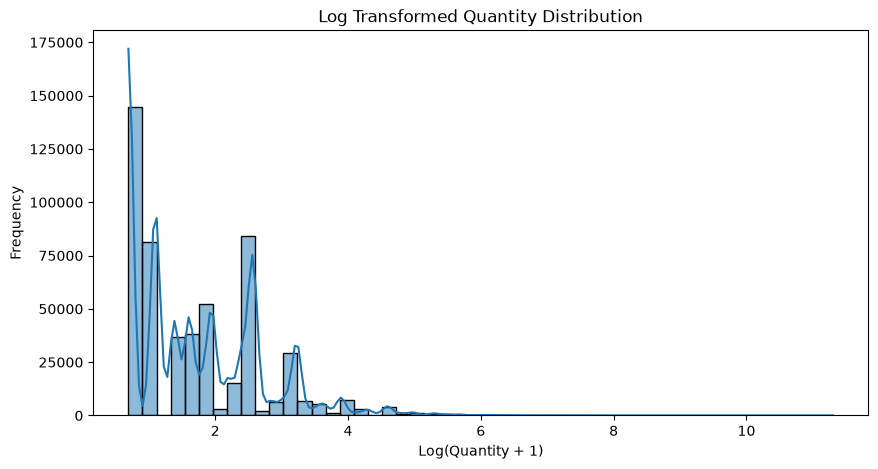

In [57]:
import numpy as np
plt.figure(figsize=(10, 5))

sns.histplot(
    np.log1p(df_clean['Quantity']),
    bins=50,
    kde=True
)

plt.title('Log Transformed Quantity Distribution')
plt.xlabel('Log(Quantity + 1)')
plt.ylabel('Frequency')

plt.show()

In [58]:
df_clean.nlargest(15, 'Quantity')[
    ['StockCode', 'Description', 'Quantity', 'UnitPrice', 'Country']
]

,StockCode,Description,Quantity,UnitPrice,Country
540421,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,United Kingdom
61619,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,United Kingdom
502122,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,United Kingdom
74614,37413,ICON MUG REVOLUTIONARY,5568,0.00,United Kingdom
421632,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,United Kingdom
206121,22197,SMALL POPCORN HOLDER,4300,0.72,United Kingdom
220843,85123A,?,4000,0.00,United Kingdom
97432,22053,EMPIRE DESIGN ROSETTE,3906,0.82,United Kingdom
270885,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,United Kingdom
52711,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,United Kingdom


## Log Transformation
Log transformation is a mathematical technique used to reduce skewness by compressing large numerical values.


It is used to reduce the effect of extreme values and make highly skewed distributions easier to analyse.

In [59]:
#checking outlier percentage
outlier_percentage = (len(outliers) / len(df_clean)) * 100

print("Total potential outliers:", len(outliers))
print("Outlier percentage:", round(outlier_percentage, 2), "%")

Total potential outliers: 27355
Outlier percentage: 5.2 %


In [60]:
df_clean[df_clean['Quantity'] >= 70000][
    ['InvoiceNo', 'StockCode', 'Description',
     'Quantity', 'InvoiceDate', 'UnitPrice', 'Country']
]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,Country
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,18-01-2011 10.01,1.04,United Kingdom
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,09-12-2011 9.15,2.08,United Kingdom
